# BUSN 35137 — Final Project (Group 2): Forecasting the stock-bond correlation

**Question.** Which group of predictors best forecasts next quarter's US stock-bond correlation out of sample: **A** macro fundamentals, **B** liquidity and stress, or **C** news? Does each group add anything beyond the correlation's own history and beyond the other groups?

**Target.** `target_next3m_corr` for month $t$ is the correlation of daily US stock returns (Ken French Mkt-RF + RF) and daily CRSP 10-year fixed-term Treasury returns over months $t+1$ to $t+3$. All predictors in row $t$ are known at the end of month $t$ (already lagged in `panel_monthly.csv`).

**Design**

| Window | Rows (forecast month) | Role |
|---|---|---|
| Burn-in | 1987-01 to 1999-12 (156) | Starting history only. Never scored. Its data stays in every expanding fit. |
| Validation | 2000-01 to 2017-12 (216; 214 scored) | Real-time OOS forecasts. Used for the team's design choices: best method per predictor set. |
| Test | 2018-01 to 2025-09 (93) | Real-time OOS forecasts with every choice frozen. Run **once** (`RUN_TEST`). |

* **Yearly expanding refits, identical in validation and test.** For forecast year $Y$, models are fit on rows 1987-01 to $(Y-1)$-10 and forecast rows $Y$-01 to $Y$-12. Row $t$'s target ends in month $t+3$, so at the end of January $Y$ (when the first year-$Y$ forecast is made) the newest realized target is row $(Y-1)$-10. Dropping rows $(Y-1)$-11 and -12 is the 2-row overlap rule.
* **Hyperparameters are re-tuned at every refit** by purged, blocked 5-fold CV on the data available at that point: 5 consecutive blocks, no shuffling, 2 rows dropped on each side of every held-out block.
* **The last 2 validation rows (2017-11, 2017-12) are forecast but not scored.** Their targets run into 2018 and overlap test-window targets, so scoring them would let test-period returns influence design choices.
* **Every model contains the trailing correlation.** In the linear-family models it enters unpenalized: its fit is partialled out first (Frisch–Waugh), and penalties act only on what a group adds.
* **Benchmarks:** expanding historical mean, trailing correlation (random walk), and the own-history regression (target on trailing correlation). The own-history model is the bar.

**Pre-registered decision rule (fixed before the test run).**
1. Primary metric: test $R^2$ vs. the own-history model. A group *adds value* only if the one-sided Clark–West test rejects at 5% (Newey–West, 2 lags).
2. Winner: the top-ranked group that adds value. It is a *clear* winner only if Diebold–Mariano also rejects (5%) against the runner-up; otherwise the groups are reported as not distinguishable.
3. Sign accuracy and the combination weights are secondary evidence, never tie-breakers.
4. Method check: the pre-specified headline model (equal-weight ridge + PCR) is run on every group. If the ranking holds there too, the result reflects information rather than method.
5. Second bar (reported, not part of the rule): $R^2$ and Clark–West vs. the **random walk** (forecast = trailing correlation). In validation the random walk beats the own-history regression, whose intercept is pulled toward the positive 1990s mean, so a group that beats both bars is the more convincing result. This was added before the test run.

Runtime: a few minutes on a multi-core machine (refits run in parallel over years). Tables and figures are written to `output/`.

In [1]:
import io, json, time, warnings, zipfile
from contextlib import contextmanager
from pathlib import Path

import numpy as np
import pandas as pd
from joblib import Parallel, delayed
from scipy import stats
from sklearn.cross_decomposition import PLSRegression
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import enet_path

warnings.filterwarnings("ignore", category=ConvergenceWarning)

DATA = Path("Zip File All Data")
if not DATA.exists():
    DATA = Path("Final Project") / "Zip File All Data"
OUT = DATA.parent / "output"
OUT.mkdir(exist_ok=True)

SEED = 0
FIRST, BURNIN_END, VAL_END, TEST_END = (pd.Period(m, "M") for m in ["1987-01", "1999-12", "2017-12", "2025-09"])
VAL_YEARS = list(range(2000, 2018))
TEST_YEARS = list(range(2018, 2026))
EMBARGO = 2          # target of row t covers months t+1..t+3, so the 2 latest rows of any fit sample are unrealized
N_FOLDS = 5          # purged, blocked CV at every refit
NW_LAGS = 2          # Newey-West lags: 3-month overlapping targets -> MA(2) forecast errors
COMB_WINDOW, COMB_MIN = 36, 12   # combination: trailing 36 realized errors, equal weights until 12 exist
ROLL_YEARS = 15      # robustness: rolling instead of expanding window
N_JOBS = -1
RUN_TEST = False     # flip to True ONCE, after the design is frozen

RIDGE_REL_GRID = np.logspace(-6, 2, 49)        # ridge penalty = rel * s_max^2 of the fit-sample design
ENET_REL_GRID = np.logspace(0, -3, 40)         # lasso / EN penalty = rel * alpha_max of the fit sample
ENET_L1_GRID = [0.2, 0.5, 0.8]
RF_GRID = [dict(max_depth=d, min_samples_leaf=l, max_features=f)
           for d in [2, 3, 5, None] for l in [5, 10, 20] for f in [0.33, 0.66, 1.0]]
RF_TREES = 300
GB_GRID = [dict(max_depth=d, learning_rate=lr) for d in [1, 2, 3] for lr in [0.01, 0.1]]
GB_MAX_TREES = 500


@contextmanager
def timer(label):
    t0 = time.perf_counter()
    yield
    print(f"[{label}: {time.perf_counter() - t0:.1f}s]")


import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from cycler import cycler
from IPython.display import display

pd.set_option("display.precision", 3)
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)

# ---- chart style (same as the HW2 notebook) ----
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
INK, INK2, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.linewidth": 0.8, "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "axes.titlesize": 11, "axes.titleweight": "semibold", "axes.titlelocation": "left", "axes.labelsize": 9.5,
    "axes.spines.top": False, "axes.spines.right": False, "axes.prop_cycle": cycler(color=PALETTE),
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "grid.linestyle": "-", "axes.axisbelow": True,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "xtick.labelsize": 8.5, "ytick.labelsize": 8.5, "lines.linewidth": 1.6, "lines.markersize": 5,
    "legend.frameon": False, "legend.fontsize": 8.5, "text.color": INK,
    "font.family": "sans-serif", "font.sans-serif": ["Segoe UI", "Helvetica", "Arial", "DejaVu Sans"],
    "figure.dpi": 110,
})


def zero_line(ax, vertical=False):
    (ax.axvline if vertical else ax.axhline)(0, color=MUTED, linewidth=0.9, zorder=1)


def save_table(df, name, floatfmt="{:.2f}"):
    """Write a table as CSV and as a markdown file for the paper."""
    df.to_csv(OUT / f"{name}.csv")
    cols = [str(df.index.name or "")] + [str(c) for c in df.columns]
    fmt = lambda v: floatfmt.format(v) if isinstance(v, (float, np.floating)) and np.isfinite(v) else ("" if v is None or (isinstance(v, float) and np.isnan(v)) else str(v))
    lines = ["| " + " | ".join(cols) + " |", "|" + "---|" * len(cols)]
    lines += ["| " + " | ".join([str(i)] + [fmt(v) for v in row]) + " |" for i, row in zip(df.index, df.to_numpy())]
    (OUT / f"{name}.md").write_text("\n".join(lines) + "\n", encoding="utf-8")


def save_fig(fig, name):
    fig.savefig(OUT / f"{name}.png", dpi=200, bbox_inches="tight")

## 1. Data

`panel_monthly.csv` has one row per month with the target, the trailing-correlation benchmark and every predictor, already lagged to when it would have been known. The cell restricts it to the forecast window (1987-01 to 2025-09, when all three groups have data), labels the windows and checks the row counts and missing values.

In [2]:
GROUPS = {
    "A": ["infl_yoy", "infl_vol12", "exp_infl_mich", "unemp_chg12", "tbill", "term_spread"],
    "B": ["credit_spread", "cp_spread", "vix_monthend", "treasury_noise", "ps_liquidity"],
    "C": ["epu_overall", "epu_monetary", "emv_inflation_share", "emv_rates_share", "emv_monetary_share",
          "emv_macro_news_share"],
    "D": ["wsj_Federal Reserve", "wsj_Recession", "wsj_Oil market", "wsj_Treasury bonds", "wsj_Financial crisis",
          "wsj_Government budgets"],
}
GROUP_NAMES = {"A": "Macro", "B": "Liquidity", "C": "News", "D": "WSJ topics"}
# predictor sets for the main analysis: each group alone, every pair, all three
SETS = {"A": ["A"], "B": ["B"], "C": ["C"], "A+B": ["A", "B"], "A+C": ["A", "C"], "B+C": ["B", "C"],
        "A+B+C": ["A", "B", "C"]}
set_cols = lambda s: [c for g in SETS[s] for c in GROUPS[g]]

panel = pd.read_csv(DATA / "panel_monthly.csv")
panel["month"] = pd.PeriodIndex(panel["month"], freq="M")
panel = panel.set_index("month")
df = panel.loc[FIRST:TEST_END].rename(columns={"target_next3m_corr": "y", "bench_trailing3m_corr": "h"})
df["window"] = np.select([df.index <= BURNIN_END, df.index <= VAL_END], ["burn-in", "validation"], "test")

VAL_SCORE_END = VAL_END - EMBARGO          # 2017-10: last validation row whose target ends before test targets start
val_idx = df.loc[pd.Period("2000-01", "M"):VAL_SCORE_END].index
test_idx = df.loc[pd.Period("2018-01", "M"):TEST_END].index
assert (df["window"].value_counts()[["burn-in", "validation", "test"]] == [156, 216, 93]).all()
assert len(val_idx) == 214 and val_idx[-1] + 3 < test_idx[0] + 1     # scored validation targets end before test targets begin
abc = [c for g in "ABC" for c in GROUPS[g]]
assert df[["y", "h"] + abc].notna().all().all(), "A/B/C, target and benchmark must be complete in the window"
print(f"Forecast window {df.index[0]} to {df.index[-1]}: {len(df)} rows; "
      f"WSJ topics available through {df[GROUPS['D']].dropna().index[-1]}")

summary = df.groupby("window", sort=False)["y"].agg(["count", "mean", "std", "min", "max"])
summary["share > 0 (%)"] = df.groupby("window", sort=False)["y"].apply(lambda s: 100 * (s > 0).mean())
summary.index.name = "window"
display(summary.round(3))
display(df.groupby("window", sort=False)[abc].mean().T.round(3))

Forecast window 1987-01 to 2025-09: 465 rows; WSJ topics available through 2017-06


,count,mean,std,min,max,share > 0 (%)
window,,,,,,
burn-in,156,0.346,0.281,-0.601,0.748,86.538
validation,216,-0.342,0.270,-0.793,0.257,13.889
test,93,-0.136,0.323,-0.653,0.489,32.258


window,burn-in,validation,test
infl_yoy,3.209,2.149,3.430
infl_vol12,0.176,0.356,0.304
exp_infl_mich,3.140,2.973,3.554
unemp_chg12,-0.214,0.009,-0.030
tbill,5.313,1.589,2.529
term_spread,1.792,1.944,0.281
credit_spread,0.841,1.057,0.894
cp_spread,0.569,0.300,0.152
vix_monthend,19.771,19.871,19.950
treasury_noise,3.727,2.905,1.941


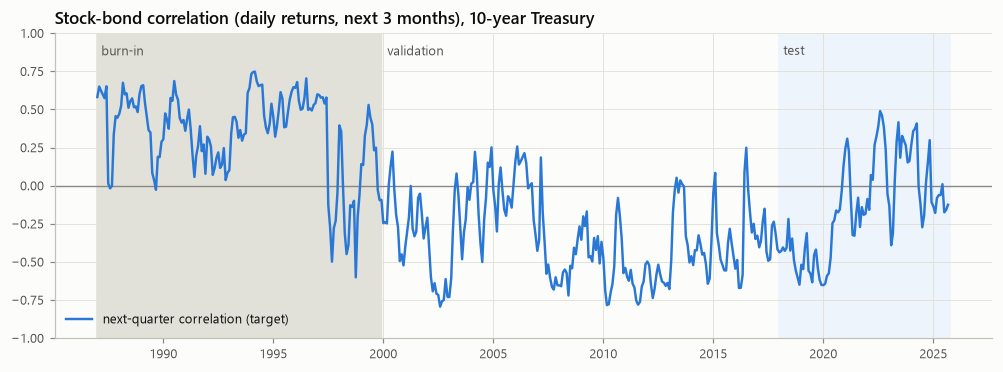

In [3]:
fig, ax = plt.subplots(figsize=(11, 3.6))
t = df.index.to_timestamp()
for lo, hi, lab in [("1987-01", "1999-12", "burn-in"), ("2000-01", "2017-12", "validation"), ("2018-01", "2025-09", "test")]:
    ax.axvspan(pd.Period(lo, "M").to_timestamp(), pd.Period(hi, "M").to_timestamp(how="end"),
               color={"burn-in": GRID, "validation": SURFACE, "test": "#eef4fc"}[lab], zorder=0)
    ax.text(pd.Period(lo, "M").to_timestamp(), 0.92, " " + lab, color=INK2, fontsize=8.5, va="top")
ax.plot(t, df["y"], color=PALETTE[0], label="next-quarter correlation (target)")
zero_line(ax)
ax.set_ylim(-1, 1)
ax.set_title("Stock-bond correlation (daily returns, next 3 months), 10-year Treasury")
ax.legend(loc="lower left")
save_fig(fig, "fig_correlation_history")
plt.show()

## 2. Rebuilding the target from daily data

The 5- and 30-year robustness checks need the target and trailing correlation for other maturities, so the target is rebuilt from the raw daily files: Ken French daily Mkt-RF + RF and CRSP fixed-term Treasury index returns (`TDRETADJ`, in %). The rebuilt 10-year series must reproduce the panel's columns exactly before the 5- and 30-year series are used.

In [4]:
with zipfile.ZipFile(DATA / "T1_Stock_Returns_Daily_KenFrench.zip") as z:
    lines = z.read(z.namelist()[0]).decode("latin-1").splitlines()
rows = [l for l in lines if len(l.split(",")[0].strip()) == 8 and l.split(",")[0].strip().isdigit()]
ff = pd.read_csv(io.StringIO("\n".join(rows)), header=None, names=["d", "mkt_rf", "smb", "hml", "rf"])
stock = pd.Series((ff["mkt_rf"] + ff["rf"]).to_numpy(), index=pd.to_datetime(ff["d"].astype(str)), name="stock")

with zipfile.ZipFile(DATA / "T2_Treasury_Returns_Daily_CRSP_FixedTerm.zip") as z:
    name = next(n for n in z.namelist() if n.endswith(".csv") and n.upper() != "EMVMACRONEWS.CSV")
    tr = pd.read_csv(z.open(name), usecols=["KYTREASNOX", "CALDT", "TDRETADJ"]).dropna(subset=["TDRETADJ"])
tr["CALDT"] = pd.to_datetime(tr["CALDT"])
bonds = tr.pivot(index="CALDT", columns="KYTREASNOX", values="TDRETADJ")
MATURITY_CODE = {"5Y": 2000005, "10Y": 2000007, "30Y": 2000009}


def corr_series(bond):
    """Return (target, trailing) monthly series: corr over months t+1..t+3 and over t-2..t."""
    d = pd.concat([stock, bond], axis=1, join="inner").dropna()
    d.columns = ["s", "b"]
    m = d.index.to_period("M")
    months = pd.period_range(panel.index[0], panel.index[-1], freq="M")
    # monthly sums for a rolling 3-month Pearson correlation
    g = pd.DataFrame({"n": 1, "s": d["s"], "b": d["b"], "ss": d["s"] ** 2, "bb": d["b"] ** 2,
                      "sb": d["s"] * d["b"]}).groupby(m).sum().reindex(months, fill_value=0)
    r = g.rolling(3).sum()
    cov = r["sb"] - r["s"] * r["b"] / r["n"]
    corr3 = cov / np.sqrt((r["ss"] - r["s"] ** 2 / r["n"]) * (r["bb"] - r["b"] ** 2 / r["n"]))
    corr3[r["n"] < 20] = np.nan                    # corr3 at month m covers m-2..m
    return corr3.shift(-3), corr3                  # target(t) = corr over t+1..t+3 = corr3 at t+3


targets = {k: corr_series(bonds[c]) for k, c in MATURITY_CODE.items()}
for col, s in [("target_next3m_corr", targets["10Y"][0]), ("bench_trailing3m_corr", targets["10Y"][1])]:
    diff = (s - panel[col]).dropna().abs()
    print(f"10Y rebuilt vs panel {col}: {len(diff)} months compared, max abs difference {diff.max():.2e}")
    assert diff.max() < 1e-10 and s.loc[FIRST:TEST_END].notna().all()
print(pd.DataFrame({k: v[0].loc[FIRST:TEST_END].describe() for k, v in targets.items()}).T.round(3))

10Y rebuilt vs panel target_next3m_corr: 489 months compared, max abs difference 3.44e-15
10Y rebuilt vs panel bench_trailing3m_corr: 490 months compared, max abs difference 3.44e-15
     count   mean    std    min    25%    50%    75%    max
5Y   465.0 -0.078  0.400 -0.795 -0.413 -0.123  0.271  0.739
10Y  465.0 -0.070  0.417 -0.793 -0.427 -0.100  0.299  0.748
30Y  465.0 -0.055  0.414 -0.812 -0.396 -0.086  0.300  0.739


## 3. Methods and the recursive forecasting loop

Every method maps a fitting sample to forecasts for **every point of its hyperparameter grid at once**. The same function serves the CV folds and the final refit, so tuning and forecasting cannot differ in how a model is built.

| Method | Specification | Grid (re-tuned by purged blocked 5-fold CV at each refit) |
|---|---|---|
| Own history (benchmark) | OLS of the target on the trailing correlation | — |
| Historical mean (benchmark) | mean of the fit-sample target | — |
| Trailing correlation (benchmark) | forecast = trailing correlation | — |
| OLS | OLS on trailing correlation + group predictors | — |
| Ridge | Frisch–Waugh residuals, standardized; closed-form SVD path (as in HW2) | 49 penalties, $\alpha = \text{rel}\times s_{\max}^2$, rel $\in [10^{-6}, 10^{2}]$ |
| Lasso / Elastic net | same residuals; `enet_path` | 40 penalties, $\alpha = \text{rel}\times\alpha_{\max}$, rel $\in [10^{-3}, 1]$; EN `l1_ratio` $\in \{0.2, 0.5, 0.8\}$ |
| PCR | same residuals; first $k$ principal components | $k \in \{0, \dots, p\}$ ($k = 0$ is own history) |
| PLS | same residuals; `PLSRegression(scale=False)` | $k \in \{0, \dots, p\}$ |
| Random forest | trailing correlation + group predictors | depth $\in\{2,3,5,\text{None}\}$ × min leaf $\in\{5,10,20\}$ × max features $\in\{0.33,0.66,1\}$; 300 trees |
| Gradient boosting | trailing correlation + group predictors, `subsample = 0.8` | depth $\in\{1,2,3\}$ × learning rate $\in\{0.01,0.1\}$; trees $\le 500$ via `staged_predict` |
| **Headline** (pre-specified) | equal-weight average of the ridge and PCR forecasts | inherits both |

Relative penalties (rel × $s_{\max}^2$, rel × $\alpha_{\max}$) keep a "penalty level" comparable as the fitting sample grows. Ridge at its largest penalty, lasso at rel = 1 and PCR/PLS at $k = 0$ all reproduce the own-history model, so every penalized method can choose to add nothing.

In [5]:
# Every method maps a fit sample (X, h, y) and an evaluation sample (X_e, h_e) to forecasts for EVERY point of its
# hyperparameter grid at once: an array of shape (n_eval, n_grid). Tuning and refitting both go through this one
# function, so CV and the final fit can never differ in how the model is built.
#   X: group predictors, h: trailing correlation (own history), y: next-quarter correlation.

def _design(h):
    return np.column_stack([np.ones(len(h)), h])

def partial_out(X, h, y, X_e, h_e):
    """Frisch-Waugh: remove the own-history fit from y and X, standardize the residual predictors.
    Returns residualized/standardized fit and eval predictors, the residual target, and the own-history
    forecast for the eval rows. Penalties then act only on what the group adds beyond own history."""
    H, H_e = _design(h), _design(h_e)
    b, *_ = np.linalg.lstsq(H, y, rcond=None)
    G, *_ = np.linalg.lstsq(H, X, rcond=None)
    Xr, Xr_e = X - H @ G, X_e - H_e @ G
    sd = Xr.std(axis=0)
    sd[sd == 0] = 1.0
    return Xr / sd, Xr_e / sd, y - H @ b, H_e @ b


class OwnHistory:
    name, grid = "Own history", [None]
    def predict_grid(self, X, h, y, X_e, h_e):
        b, *_ = np.linalg.lstsq(_design(h), y, rcond=None)
        return (_design(h_e) @ b)[:, None]
    def describe(self, k): return "—"


class HistMean:
    name, grid = "Historical mean", [None]
    def predict_grid(self, X, h, y, X_e, h_e):
        return np.full((len(h_e), 1), y.mean())
    def describe(self, k): return "—"


class OLS:
    name, grid = "OLS", [None]
    def predict_grid(self, X, h, y, X_e, h_e):
        Z = np.column_stack([_design(h), X])
        b, *_ = np.linalg.lstsq(Z, y, rcond=None)
        return (np.column_stack([_design(h_e), X_e]) @ b)[:, None]
    def describe(self, k): return "—"


class Ridge:
    name, grid = "Ridge", list(RIDGE_REL_GRID)
    def predict_grid(self, X, h, y, X_e, h_e):
        Z, Z_e, r, base = partial_out(X, h, y, X_e, h_e)
        U, s, Vt = np.linalg.svd(Z, full_matrices=False)
        alphas = RIDGE_REL_GRID * s[0] ** 2
        shrink = s[:, None] / (s[:, None] ** 2 + alphas[None, :])          # (p, n_grid)
        coefs = Vt.T @ (shrink * (U.T @ r)[:, None])                      # (p, n_grid)
        return base[:, None] + Z_e @ coefs
    def describe(self, k): return f"rel = {RIDGE_REL_GRID[k]:.2g}"


class ENet:
    def __init__(self, l1_grid, name):
        self.l1_grid, self.name = l1_grid, name
        self.grid = [(l1, rel) for l1 in l1_grid for rel in ENET_REL_GRID]
    def predict_grid(self, X, h, y, X_e, h_e):
        Z, Z_e, r, base = partial_out(X, h, y, X_e, h_e)
        out = []
        for l1 in self.l1_grid:
            amax = np.abs(Z.T @ r).max() / (len(r) * l1)
            _, coefs, _ = enet_path(Z, r, l1_ratio=l1, alphas=amax * ENET_REL_GRID, max_iter=5000)
            out.append(base[:, None] + Z_e @ coefs)
        return np.hstack(out)
    def describe(self, k):
        l1, rel = self.grid[k]
        return f"rel = {rel:.2g}" if len(self.l1_grid) == 1 else f"l1 = {l1}, rel = {rel:.2g}"


class PCR:
    name = "PCR"
    def __init__(self, p): self.grid = list(range(0, p + 1))          # k = 0 is own history
    def predict_grid(self, X, h, y, X_e, h_e):
        Z, Z_e, r, base = partial_out(X, h, y, X_e, h_e)
        _, _, Vt = np.linalg.svd(Z, full_matrices=False)
        F, F_e = Z @ Vt.T, Z_e @ Vt.T                       # PC scores (columns ordered by variance)
        g = (F.T @ r) / (F ** 2).sum(axis=0)                # PCs are orthogonal: univariate slopes
        steps = np.column_stack([np.zeros(len(Z_e)), np.cumsum(F_e * g, axis=1)])
        return base[:, None] + steps[:, : len(self.grid)]
    def describe(self, k): return f"k = {self.grid[k]}"


class PLS:
    name = "PLS"
    def __init__(self, p): self.grid = list(range(0, p + 1))          # k = 0 is own history
    def predict_grid(self, X, h, y, X_e, h_e):
        Z, Z_e, r, base = partial_out(X, h, y, X_e, h_e)
        cols = [np.zeros(len(Z_e))] + [PLSRegression(n_components=k, scale=False).fit(Z, r).predict(Z_e).ravel()
                                       for k in self.grid[1:]]
        return base[:, None] + np.column_stack(cols)
    def describe(self, k): return f"k = {self.grid[k]}"


class RF:
    name, grid = "Random forest", RF_GRID
    def predict_grid(self, X, h, y, X_e, h_e):
        Z, Z_e = np.column_stack([h, X]), np.column_stack([h_e, X_e])
        cols = [RandomForestRegressor(n_estimators=RF_TREES, random_state=SEED, n_jobs=1, **g).fit(Z, y).predict(Z_e)
                for g in self.grid]
        return np.column_stack(cols)
    def describe(self, k):
        g = self.grid[k]
        return f"depth = {g['max_depth']}, leaf = {g['min_samples_leaf']}, feat = {g['max_features']}"


class GB:
    name = "Gradient boosting"
    grid = [(i, n) for i in range(len(GB_GRID)) for n in range(1, GB_MAX_TREES + 1)]
    def predict_grid(self, X, h, y, X_e, h_e):
        Z, Z_e = np.column_stack([h, X]), np.column_stack([h_e, X_e])
        out = []
        for g in GB_GRID:
            m = GradientBoostingRegressor(n_estimators=GB_MAX_TREES, subsample=0.8, random_state=SEED, **g).fit(Z, y)
            out.append(np.column_stack(list(m.staged_predict(Z_e))))
        return np.hstack(out)
    def describe(self, k):
        i, n = self.grid[k]
        return f"depth = {GB_GRID[i]['max_depth']}, lr = {GB_GRID[i]['learning_rate']}, trees = {n}"


def methods_for(p):
    return {"OLS": OLS(), "Ridge": Ridge(), "Lasso": ENet([1.0], "Lasso"), "Elastic net": ENet(ENET_L1_GRID, "Elastic net"),
            "PCR": PCR(p), "PLS": PLS(p), "Random forest": RF(), "Gradient boosting": GB()}

In [6]:
def purged_block_folds(n, k=N_FOLDS, purge=EMBARGO):
    """Contiguous folds, no shuffling. Training rows within `purge` of the held-out block are dropped,
    because their 3-month targets overlap the held-out targets."""
    edges = np.linspace(0, n, k + 1).astype(int)
    idx = np.arange(n)
    for a, b in zip(edges[:-1], edges[1:]):
        train = idx[(idx < a - purge) | (idx >= b + purge)]
        yield train, idx[a:b]


def fit_rows(df, Y, window=None):
    """Rows usable for the year-Y refit. The first forecast of year Y (row Y-01) is made at the end of January Y,
    when targets of rows up to (Y-1)-10 are realized (row t's target ends in month t+3). Dropping (Y-1)-11 and
    (Y-1)-12 is the 2-row overlap rule."""
    last = pd.Period(f"{Y - 1}-12", "M") - EMBARGO
    first = FIRST if window is None else max(FIRST, last - 12 * window + 1)
    return df.loc[first:last]


def one_year(method, df, xcols, Y, end, window=None, tune=True):
    fit = fit_rows(df, Y, window)
    ev = df.loc[pd.Period(f"{Y}-01", "M"): min(pd.Period(f"{Y}-12", "M"), end)]
    # no fitting target may overlap an evaluation target: last fit target ends at fit.index[-1] + 3
    assert fit.index[-1] + 3 < ev.index[0] + 1
    X, h, y = fit[xcols].to_numpy(float), fit["h"].to_numpy(float), fit["y"].to_numpy(float)
    if tune and len(method.grid) > 1:
        sse = np.zeros(len(method.grid))
        for tr, va in purged_block_folds(len(y)):
            P = method.predict_grid(X[tr], h[tr], y[tr], X[va], h[va])
            sse += ((y[va, None] - P) ** 2).sum(axis=0)
        k = int(np.argmin(sse))
    else:
        k = 0
    P = method.predict_grid(X, h, y, ev[xcols].to_numpy(float), ev["h"].to_numpy(float))
    return pd.Series(P[:, k], index=ev.index), {"year": Y, "k": k, "grid_size": len(method.grid),
                                                 "edge": k in (0, len(method.grid) - 1) and len(method.grid) > 1,
                                                 "desc": method.describe(k), "n_fit": len(y)}


def recursive_forecasts(method, df, xcols, years, end, window=None):
    """Yearly expanding (or rolling) refits; hyperparameters re-tuned by purged blocked CV at each refit."""
    res = Parallel(n_jobs=N_JOBS)(delayed(one_year)(method, df, xcols, Y, end, window) for Y in years)
    f = pd.concat([r[0] for r in res])
    return f, pd.DataFrame([r[1] for r in res]).set_index("year")

### Evaluation tools and self-checks

* $R^2_{OOS}$ vs. a benchmark $= 1 - \text{SSE}_{\text{model}} / \text{SSE}_{\text{benchmark}}$, in %.
* **Clark–West** (one-sided): does a larger model that nests the benchmark improve on it? It uses the MSE-adjusted loss differential, which corrects for the noise a nested model adds under the null.
* **Diebold–Mariano** (two-sided): equal MSE for non-nested forecasts (group vs. group).
* Both use Newey–West standard errors with 2 lags, because consecutive 3-month targets overlap (MA(2) errors).

The checks below verify the CV purging, that the penalized models nest own history, one year's own-history fit against a hand computation, and the two tests on simulated data with a known answer.

In [7]:
def oos_r2(y, f, f_bench):
    return 100 * (1 - ((y - f) ** 2).sum() / ((y - f_bench) ** 2).sum())

def sign_acc(y, f):
    return 100 * np.mean(np.sign(y) == np.sign(f))

def nw_tstat(d, lags=NW_LAGS):
    """t-statistic of mean(d) with a Newey-West (Bartlett) long-run variance."""
    d = np.asarray(d, float)
    u, T = d - d.mean(), len(d)
    lrv = u @ u / T + 2 * sum((1 - l / (lags + 1)) * (u[l:] @ u[:-l]) / T for l in range(1, lags + 1))
    return d.mean() / np.sqrt(lrv / T) if lrv > 0 else np.nan     # nan: the two forecasts are identical

def clark_west(y, f_small, f_big):
    """One-sided test that the larger (nested) model improves on the smaller one. Returns (t, p)."""
    adj = (y - f_small) ** 2 - ((y - f_big) ** 2 - (f_small - f_big) ** 2)
    t = nw_tstat(adj)
    return t, 1 - stats.norm.cdf(t)

def diebold_mariano(y, f1, f2):
    """Two-sided test of equal MSE. t > 0 means f2 is more accurate. Returns (t, p)."""
    t = nw_tstat((y - f1) ** 2 - (y - f2) ** 2)
    return t, 2 * (1 - stats.norm.cdf(abs(t)))


# ---- self-checks ----
for tr, va in purged_block_folds(150):
    assert np.abs(tr[:, None] - va[None, :]).min() > EMBARGO          # no train target overlaps a held-out target

fit = fit_rows(df, 2005)
X, h, y = fit[GROUPS["A"]].to_numpy(float), fit["h"].to_numpy(float), fit["y"].to_numpy(float)
ev = df.loc["2005-01":"2005-12"]
Xe, he = ev[GROUPS["A"]].to_numpy(float), ev["h"].to_numpy(float)
own = OwnHistory().predict_grid(X, h, y, Xe, he)[:, 0]
slope, icpt = np.polyfit(h, y, 1)
assert np.allclose(own, icpt + slope * he)
assert np.allclose(Ridge().predict_grid(X, h, y, Xe, he)[:, -1], own, atol=1e-3)
assert np.allclose(PCR(6).predict_grid(X, h, y, Xe, he)[:, 0], own)
assert np.allclose(ENet([1.0], "Lasso").predict_grid(X, h, y, Xe, he)[:, 0], own)
print(f"2005 refit: {len(fit)} rows ({fit.index[0]} to {fit.index[-1]}); own-history fit matches np.polyfit; "
      "ridge (max penalty), lasso (rel = 1) and PCR (k = 0) reproduce own history")

rng = np.random.default_rng(SEED)
x = rng.standard_normal(400); yy = 0.3 * x + rng.standard_normal(400)
print(f"Clark-West, informative nested forecast:  p = {clark_west(yy, np.zeros(400), 0.3 * x)[1]:.4f}  (expect small)")
print(f"Clark-West, pure-noise nested forecast:   p = {clark_west(yy, np.zeros(400), 0.05 * rng.standard_normal(400))[1]:.4f}  (expect large)")
print(f"Diebold-Mariano, equally good forecasts:  p = {diebold_mariano(yy, 0.3 * x + 0.1 * rng.standard_normal(400), 0.3 * x + 0.1 * rng.standard_normal(400))[1]:.4f}  (expect large)")
print(f"Diebold-Mariano, f2 much better:          t = {diebold_mariano(yy, np.zeros(400), 0.3 * x)[0]:.2f} (expect > 0)")

2005 refit: 214 rows (1987-01 to 2004-10); own-history fit matches np.polyfit; ridge (max penalty), lasso (rel = 1) and PCR (k = 0) reproduce own history
Clark-West, informative nested forecast:  p = 0.0000  (expect small)
Clark-West, pure-noise nested forecast:   p = 0.4637  (expect large)
Diebold-Mariano, equally good forecasts:  p = 0.1042  (expect large)
Diebold-Mariano, f2 much better:          t = 4.87 (expect > 0)


## 4. Benchmarks (validation, 2000-01 to 2017-10)

All three benchmarks go through the same yearly expanding loop. The own-history model is the bar every other model has to clear.

In [8]:
F, INFO = {}, {}          # forecasts and per-year tuning info, keyed by (predictor set, method)


def run(key, method, xcols, years=VAL_YEARS, end=VAL_END, data=None, window=None):
    f, info = recursive_forecasts(method, df if data is None else data, xcols, years, end, window)
    F[key], INFO[key] = f, info
    return f


with timer("benchmarks"):
    run(("bench", "Historical mean"), HistMean(), [])
    run(("bench", "Own history"), OwnHistory(), [])
    F[("bench", "Trailing correlation")] = df.loc[F[("bench", "Own history")].index, "h"]

yv = df.loc[val_idx, "y"]
own_v = F[("bench", "Own history")].loc[val_idx]
bench_tab = pd.DataFrame({
    name: {"R2 vs hist. mean (%)": oos_r2(yv, F[("bench", name)].loc[val_idx], F[("bench", "Historical mean")].loc[val_idx]),
           "R2 vs own history (%)": oos_r2(yv, F[("bench", name)].loc[val_idx], own_v),
           "RMSE": np.sqrt(((yv - F[("bench", name)].loc[val_idx]) ** 2).mean()),
           "sign accuracy (%)": sign_acc(yv, F[("bench", name)].loc[val_idx])}
    for name in ["Historical mean", "Trailing correlation", "Own history"]}).T
bench_tab.index.name = "benchmark"
display(bench_tab.round(2))
save_table(bench_tab, "table_benchmarks_validation")
slopes = pd.DataFrame({Y: np.polyfit(fit_rows(df, Y)["h"], fit_rows(df, Y)["y"], 1) for Y in VAL_YEARS},
                      index=["own-history slope", "intercept"]).T
print("Own-history coefficients by refit year (persistence of the correlation):")
display(slopes.iloc[::3].round(3).T)

[benchmarks: 1.6s]


,R2 vs hist. mean (%),R2 vs own history (%),RMSE,sign accuracy (%)
benchmark,,,,
Historical mean,0.00,-243.92,0.54,32.71
Trailing correlation,72.82,6.53,0.28,80.37
Own history,70.92,0.00,0.29,76.64


Own-history coefficients by refit year (persistence of the correlation):


,2000,2003,2006,2009,2012,2015
own-history slope,0.503,0.770,0.730,0.773,0.809,0.814
intercept,0.172,0.037,0.039,0.015,-0.004,-0.011


## 5. Method grid on validation (Table 2)

Every method is run on every predictor set (each group alone, every pair, all three) with the same loop. The score is the validation $R^2$ vs. the own-history model. For each set, the method with the highest validation $R^2$ (lowest MSE) is marked `*` and carried forward to the test. The headline model is pre-specified and reported alongside; it is not a candidate in the selection.

In [9]:
METHOD_ORDER = ["OLS", "Ridge", "Lasso", "Elastic net", "PCR", "PLS", "Random forest", "Gradient boosting"]

with timer("method grid, 7 predictor sets x 8 methods"):
    for s in SETS:
        cols = set_cols(s)
        for mname, m in methods_for(len(cols)).items():
            run((s, mname), m, cols)
        F[(s, "Headline")] = (F[(s, "Ridge")] + F[(s, "PCR")]) / 2


def score(keys, idx, bench_own, bench_mean, data=None):
    """Second bar: the random walk (forecast = trailing correlation). Every model nests it (intercept 0, slope 1,
    group coefficients 0), so Clark-West applies. It is reported, but the decision rule uses own history."""
    d = df if data is None else data
    y_, rw = d.loc[idx, "y"], d.loc[idx, "h"]
    rows = {}
    for k in keys:
        f = F[k].loc[idx]
        rows[k] = {"R2 vs own (%)": oos_r2(y_, f, bench_own.loc[idx]),
                   "R2 vs RW (%)": oos_r2(y_, f, rw),
                   "R2 vs mean (%)": oos_r2(y_, f, bench_mean.loc[idx]),
                   "sign (%)": sign_acc(y_, f),
                   "CW p vs own": clark_west(y_.to_numpy(), bench_own.loc[idx].to_numpy(), f.to_numpy())[1],
                   "CW p vs RW": clark_west(y_.to_numpy(), rw.to_numpy(), f.to_numpy())[1]}
    return pd.DataFrame(rows).T


val = score([(s, m) for s in SETS for m in METHOD_ORDER + ["Headline"]], val_idx,
            F[("bench", "Own history")], F[("bench", "Historical mean")])
SELECTED = {s: val.loc[s].loc[METHOD_ORDER, "R2 vs own (%)"].idxmax() for s in SETS}


def grid_table(col, fmt="{:.2f}", star=True):
    t = val[col].unstack(0)[list(SETS)].loc[METHOD_ORDER + ["Headline"]]
    out = t.map(lambda v: fmt.format(v))
    if star:
        for s, m in SELECTED.items():
            out.loc[m, s] += "*"
    out.columns = [f"{s} ({'+'.join(GROUP_NAMES[g] for g in SETS[s])})" if len(SETS[s]) == 1 else s for s in out.columns]
    out.index.name = "method"
    return out


table2 = grid_table("R2 vs own (%)")
print("Table 2. Validation R2 (%) vs. the own-history model, 2000-01 to 2017-10. * = best method for the set "
      "(carried to test).")
display(table2)
save_table(table2, "table2_validation_r2_vs_own")
print("Clark-West p-values vs. own history (one-sided):")
display(grid_table("CW p vs own", "{:.3f}", star=False))
save_table(grid_table("CW p vs own", "{:.3f}", star=False), "table2b_validation_cw_p")
print("Second bar: validation R2 (%) vs. the random walk (forecast = trailing correlation). "
      f"Own history itself: {oos_r2(yv, own_v, df.loc[val_idx, 'h']):.2f}%.")
display(grid_table("R2 vs RW (%)", star=False))
save_table(grid_table("R2 vs RW (%)", star=False), "table2c_validation_r2_vs_rw")
print("Clark-West p-values vs. the random walk (one-sided):")
display(grid_table("CW p vs RW", "{:.3f}", star=False))
save_table(grid_table("CW p vs RW", "{:.3f}", star=False), "table2d_validation_cw_p_vs_rw")
print("Sign accuracy (%):  own history =", round(sign_acc(yv, own_v), 1))
display(grid_table("sign (%)", "{:.1f}", star=False))
print("Selected method per set:", SELECTED)

[method grid, 7 predictor sets x 8 methods: 499.3s]
Table 2. Validation R2 (%) vs. the own-history model, 2000-01 to 2017-10. * = best method for the set (carried to test).


,A (Macro),B (Liquidity),C (News),A+B,A+C,B+C,A+B+C
method,,,,,,,
OLS,-25.52,-22.95,9.04*,-53.34,-23.82,-19.00,-46.94
Ridge,-10.10*,-0.02,6.26,0.77,-2.90,3.65,3.63
Lasso,-14.67,0.00*,6.76,1.31,9.91*,-0.15,3.94
Elastic net,-13.64,0.00,6.63,1.44*,8.68,-0.69,5.96*
PCR,-21.20,0.00,8.38,1.42,-16.36,3.79,-2.25
PLS,-25.94,0.00,8.11,0.00,-23.56,4.43*,1.01
Random forest,-49.08,-53.97,-14.85,-52.83,-43.29,-35.63,-48.92
Gradient boosting,-45.67,-57.26,-4.80,-46.56,-28.99,-18.77,-33.67
Headline,-14.60,-0.01,7.62,1.12,-8.56,4.13,1.68


Clark-West p-values vs. own history (one-sided):


,A (Macro),B (Liquidity),C (News),A+B,A+C,B+C,A+B+C
method,,,,,,,
OLS,0.018,0.975,0.000,0.099,0.004,0.257,0.066
Ridge,0.054,0.954,0.003,0.039,0.002,0.025,0.015
Lasso,0.042,nan,0.003,0.053,0.000,0.168,0.013
Elastic net,0.037,nan,0.003,0.042,0.000,0.197,0.003
PCR,0.034,nan,0.001,0.066,0.014,0.012,0.146
PLS,0.070,nan,0.001,nan,0.004,0.011,0.157
Random forest,0.883,0.996,0.424,0.933,0.850,0.927,0.896
Gradient boosting,0.832,0.969,0.020,0.689,0.445,0.352,0.525
Headline,0.039,0.954,0.001,0.053,0.006,0.016,0.063


Second bar: validation R2 (%) vs. the random walk (forecast = trailing correlation). Own history itself: -6.99%.


,A (Macro),B (Liquidity),C (News),A+B,A+C,B+C,A+B+C
method,,,,,,,
OLS,-34.29,-31.55,2.68,-64.06,-32.48,-27.32,-57.21
Ridge,-17.80,-7.02,-0.30,-6.17,-10.09,-3.09,-3.10
Lasso,-22.69,-6.99,0.24,-5.59,3.62,-7.15,-2.78
Elastic net,-21.58,-6.99,0.10,-5.46,2.30,-7.73,-0.62
PCR,-29.67,-6.99,1.98,-5.47,-24.50,-2.94,-9.40
PLS,-34.75,-6.99,1.69,-6.99,-32.20,-2.25,-5.91
Random forest,-59.50,-64.74,-22.88,-63.51,-53.31,-45.11,-59.34
Gradient boosting,-55.85,-68.26,-12.13,-56.81,-38.01,-27.08,-43.02
Headline,-22.61,-7.00,1.17,-5.79,-16.15,-2.58,-5.19


Clark-West p-values vs. the random walk (one-sided):


,A (Macro),B (Liquidity),C (News),A+B,A+C,B+C,A+B+C
method,,,,,,,
OLS,0.001,0.032,0.000,0.009,0.001,0.001,0.004
Ridge,0.006,0.011,0.000,0.008,0.001,0.002,0.002
Lasso,0.006,0.011,0.000,0.007,0.000,0.004,0.004
Elastic net,0.006,0.011,0.000,0.006,0.001,0.004,0.002
PCR,0.003,0.011,0.000,0.007,0.001,0.003,0.001
PLS,0.012,0.011,0.000,0.011,0.002,0.002,0.006
Random forest,0.003,0.023,0.000,0.004,0.001,0.001,0.001
Gradient boosting,0.003,0.004,0.000,0.001,0.001,0.000,0.001
Headline,0.004,0.011,0.000,0.007,0.001,0.002,0.001


Sign accuracy (%):  own history = 76.6


,A (Macro),B (Liquidity),C (News),A+B,A+C,B+C,A+B+C
method,,,,,,,
OLS,77.6,75.7,81.3,74.8,81.8,76.6,78.5
Ridge,77.6,76.6,79.4,76.6,78.5,79.0,79.0
Lasso,77.6,76.6,81.3,77.1,78.5,78.5,78.0
Elastic net,78.0,76.6,81.3,77.6,78.5,78.5,78.5
PCR,79.9,76.6,78.5,77.1,77.1,78.0,77.1
PLS,77.1,76.6,79.4,76.6,79.9,78.5,77.1
Random forest,68.7,67.8,78.0,70.1,74.8,72.0,74.3
Gradient boosting,68.2,67.3,79.9,71.5,77.1,77.6,72.0
Headline,78.5,76.6,78.0,76.6,78.0,79.0,77.6


Selected method per set: {'A': 'Ridge', 'B': 'Lasso', 'C': 'OLS', 'A+B': 'Elastic net', 'A+C': 'Lasso', 'B+C': 'PLS', 'A+B+C': 'Elastic net'}


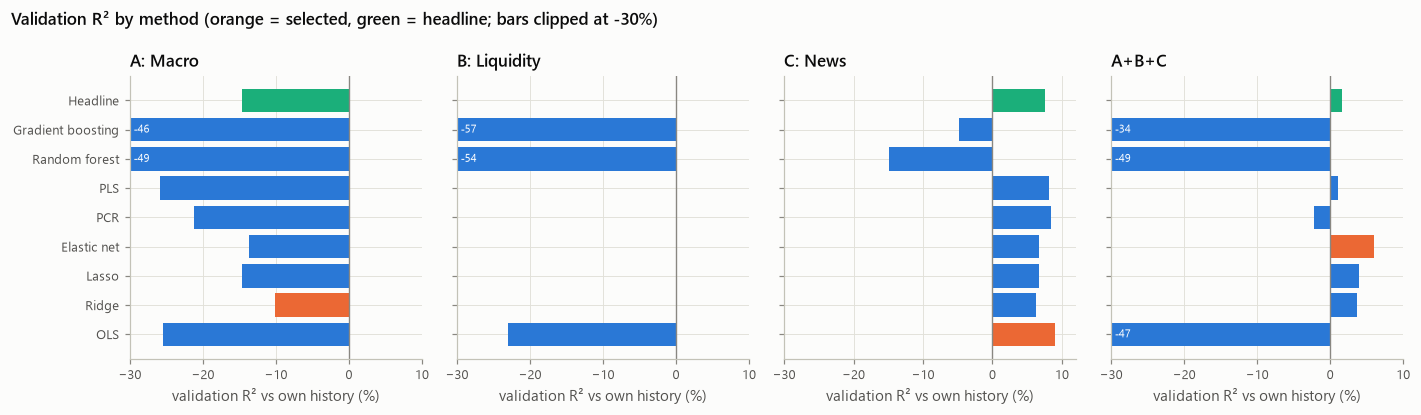

In [10]:
fig, axes = plt.subplots(1, 4, figsize=(13, 3.8), sharey=True)
for ax, s in zip(axes, ["A", "B", "C", "A+B+C"]):
    v = val.loc[s].loc[METHOD_ORDER + ["Headline"], "R2 vs own (%)"]
    colors = [PALETTE[1] if m == SELECTED[s] else (PALETTE[2] if m == "Headline" else PALETTE[0]) for m in v.index]
    ax.barh(range(len(v)), v.clip(lower=-30), color=colors)
    for i, x in enumerate(v):
        if x < -30:
            ax.text(-29.5, i, f"{x:.0f}", va="center", fontsize=7.5, color="white")
    ax.set_yticks(range(len(v)), v.index)
    ax.invert_yaxis()
    zero_line(ax, vertical=True)
    ax.set_xlim(-30, max(10, v.max() + 3))
    ax.set_title(s if len(SETS[s]) > 1 else f"{s}: {GROUP_NAMES[s]}")
    ax.set_xlabel("validation R² vs own history (%)")
fig.suptitle("Validation R² by method (orange = selected, green = headline; bars clipped at -30%)", x=0.01, ha="left",
             fontsize=11, fontweight="semibold")
fig.tight_layout()
save_fig(fig, "fig_validation_r2_by_method")
plt.show()

A      B     C    A+B   A+C   B+C  A+B+C
method      share of refits choosing                                             
Ridge       own-history end (%)       22.0  100.0   0.0   61.0   6.0  22.0   11.0
            least-shrinkage end (%)    0.0    0.0  11.0    0.0   0.0   0.0    0.0
Lasso       own-history end (%)       61.0  100.0   6.0   78.0   6.0  11.0   22.0
            least-shrinkage end (%)    0.0    0.0  11.0    0.0   0.0   0.0    0.0
Elastic net own-history end (%)       44.0  100.0   0.0   61.0   0.0  11.0   17.0
            least-shrinkage end (%)    0.0    0.0  11.0    0.0   0.0   0.0    0.0
PCR         own-history end (%)       22.0  100.0   0.0   78.0   6.0  39.0   28.0
            least-shrinkage end (%)    0.0    0.0   6.0    0.0   6.0   0.0    0.0
PLS         own-history end (%)       78.0  100.0  17.0  100.0  22.0  56.0   83.0
            least-shrinkage end (%)    0.0    0.0   6.0    0.0   0.0   0.0    0.0

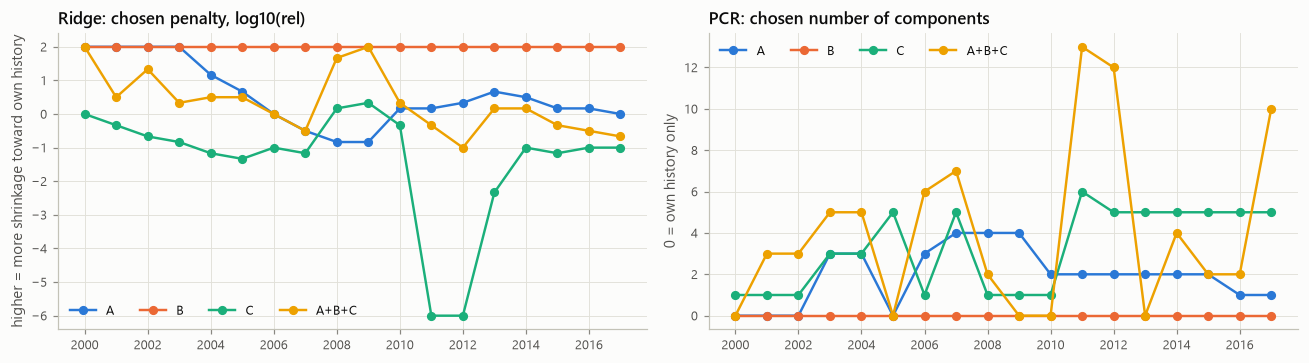

In [11]:
# Hyperparameters chosen at each refit: how aggressive were the models over time?
# Grid ends: the "own-history end" (max penalty / k = 0) means "this set adds nothing", which is a legitimate
# answer, not a grid problem. Hitting the OTHER end (least shrinkage / all components) would suggest the grid
# is too narrow. Any widening must be decided on validation evidence, before the test.
def grid_ends(s, m):
    k, n = INFO[(s, m)]["k"].to_numpy(), INFO[(s, m)]["grid_size"].iloc[0]
    if m == "Ridge":
        own, other = k == n - 1, k == 0
    elif m in ("Lasso", "Elastic net"):
        j = k % len(ENET_REL_GRID)
        own, other = j == 0, j == len(ENET_REL_GRID) - 1
    else:                                    # PCR / PLS
        own, other = k == 0, k == n - 1
    return 100 * own.mean(), 100 * other.mean()


ends = {}
for m in ["Ridge", "Lasso", "Elastic net", "PCR", "PLS"]:
    for s in SETS:
        ends[(m, "own-history end (%)")] = ends.get((m, "own-history end (%)"), {}) | {s: grid_ends(s, m)[0]}
        ends[(m, "least-shrinkage end (%)")] = ends.get((m, "least-shrinkage end (%)"), {}) | {s: grid_ends(s, m)[1]}
ends = pd.DataFrame(ends).T
ends.index.names = ["method", "share of refits choosing"]
display(ends.round(0))
save_table(ends, "table_grid_ends_validation", "{:.0f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.4))
for s, c in zip(["A", "B", "C", "A+B+C"], PALETTE):
    axes[0].plot(VAL_YEARS, np.log10(RIDGE_REL_GRID[INFO[(s, "Ridge")]["k"]]), marker="o", color=c, label=s)
    axes[1].plot(VAL_YEARS, INFO[(s, "PCR")]["k"], marker="o", color=c, label=s)      # grid index = components
axes[0].set_title("Ridge: chosen penalty, log10(rel)")
axes[0].set_ylabel("higher = more shrinkage toward own history")
axes[1].set_title("PCR: chosen number of components")
axes[1].set_ylabel("0 = own history only")
for ax in axes:
    ax.legend(ncol=4)
    ax.xaxis.set_major_locator(mticker.MultipleLocator(2))
fig.tight_layout()
save_fig(fig, "fig_hyperparameters_over_time")
plt.show()

## 6. Nested models and group comparisons (validation)

* **Each set vs. own history:** validation $R^2$ and Clark–West, with the selected method and with the headline method.
* **Incremental value:** Clark–West tests of a larger set against each set it nests, e.g. A+B vs. A asks whether liquidity adds to macro. Both forecasts use the headline method so that only the information differs.
* **Group vs. group:** Diebold–Mariano for A vs. B vs. C (headline method and selected method).

In [12]:
y_v = df.loc[val_idx, "y"].to_numpy()
nested = pd.DataFrame({s: {"selected method": SELECTED[s],
                           "R2 vs own, selected (%)": val.loc[(s, SELECTED[s]), "R2 vs own (%)"],
                           "CW p, selected": val.loc[(s, SELECTED[s]), "CW p vs own"],
                           "R2 vs RW, selected (%)": val.loc[(s, SELECTED[s]), "R2 vs RW (%)"],
                           "CW p vs RW, selected": val.loc[(s, SELECTED[s]), "CW p vs RW"],
                           "R2 vs own, headline (%)": val.loc[(s, "Headline"), "R2 vs own (%)"],
                           "CW p, headline": val.loc[(s, "Headline"), "CW p vs own"],
                           "R2 vs RW, headline (%)": val.loc[(s, "Headline"), "R2 vs RW (%)"]} for s in SETS}).T
nested.index.name = "own history +"
display(nested)
save_table(nested, "table_nested_validation", "{:.3f}")

inc = {}
for big in SETS:
    for small in SETS:
        if set(SETS[small]) < set(SETS[big]):
            fs, fb = F[(small, "Headline")].loc[val_idx].to_numpy(), F[(big, "Headline")].loc[val_idx].to_numpy()
            t, p = clark_west(y_v, fs, fb)
            added = "+".join(g for g in SETS[big] if g not in SETS[small])
            inc[f"{big} vs {small}"] = {"adds": f"{added} ({', '.join(GROUP_NAMES[g] for g in added.split('+'))})",
                                        "R2 gain (%)": oos_r2(df.loc[val_idx, "y"], fb, fs), "CW t": t, "CW p": p}
inc = pd.DataFrame(inc).T
inc.index.name = "headline: larger vs nested"
display(inc)
save_table(inc, "table_incremental_validation", "{:.3f}")

dm = {}
for a, b in [("A", "B"), ("A", "C"), ("B", "C")]:
    for meth in ["Headline", "selected"]:
        fa = F[(a, SELECTED[a] if meth == "selected" else meth)].loc[val_idx].to_numpy()
        fb = F[(b, SELECTED[b] if meth == "selected" else meth)].loc[val_idx].to_numpy()
        t, p = diebold_mariano(y_v, fa, fb)
        dm[(f"{a} vs {b}", meth)] = {"DM t (>0: second better)": t, "p": p}
dm = pd.DataFrame(dm).T
dm.index.names = ["comparison", "method"]
display(dm.round(3))
save_table(dm, "table_dm_validation", "{:.3f}")

,selected method,"R2 vs own, selected (%)","CW p, selected","R2 vs RW, selected (%)","CW p vs RW, selected","R2 vs own, headline (%)","CW p, headline","R2 vs RW, headline (%)"
own history +,,,,,,,,
A,Ridge,-10.098,0.054,-17.796,0.006,-14.601,0.039,-22.614
B,Lasso,0.0,NaN,-6.992,0.011,-0.011,0.954,-7.003
C,OLS,9.035,0.0,2.675,0.0,7.625,0.001,1.166
A+B,Elastic net,1.435,0.042,-5.456,0.006,1.123,0.053,-5.791
A+C,Lasso,9.914,0.0,3.615,0.0,-8.558,0.006,-16.148
B+C,PLS,4.433,0.011,-2.248,0.002,4.128,0.016,-2.575
A+B+C,Elastic net,5.956,0.003,-0.62,0.002,1.684,0.063,-5.19


,adds,R2 gain (%),CW t,CW p
headline: larger vs nested,,,,
A+B vs A,B (Liquidity),13.72,2.165,0.015
A+B vs B,A (Macro),1.133,1.633,0.051
A+C vs A,C (News),5.273,2.697,0.004
A+C vs C,A (Macro),-17.519,1.237,0.108
B+C vs B,C (News),4.138,2.152,0.016
B+C vs C,B (Liquidity),-3.786,-0.285,0.612
A+B+C vs A,"B+C (Liquidity, News)",14.21,2.267,0.012
A+B+C vs B,"A+C (Macro, News)",1.695,1.534,0.063
A+B+C vs C,"A+B (Macro, Liquidity)",-6.431,-0.095,0.538


DM t (>0: second better)      p
comparison method                                   
A vs B     Headline                     1.724  0.085
           selected                     1.709  0.087
A vs C     Headline                     2.376  0.017
           selected                     2.489  0.013
B vs C     Headline                     1.526  0.127
           selected                     1.554  0.120

## 7. Accuracy-weighted combination of the three groups

At each forecast month $t$ the combination weights each group's forecast (own history + that group) by the inverse of its MSE over the last 36 **realized** forecast errors. Row $s$'s error is known only once its target ends (month $s+3$), so the weights at $t$ use rows up to $t-3$. Weights are equal until 12 errors exist. The window (36) and minimum (12) are fixed here and never tuned. The combination is built from the selected method of each group and, as the method check, from the headline method.

R2 vs own (%)  R2 vs RW (%)  R2 vs mean (%)  sign (%)  CW p vs own  CW p vs RW
Combination selected          5.969        -0.605          72.659    78.972        0.000       0.001
            Headline          4.753        -1.906          72.306    78.505        0.001       0.001

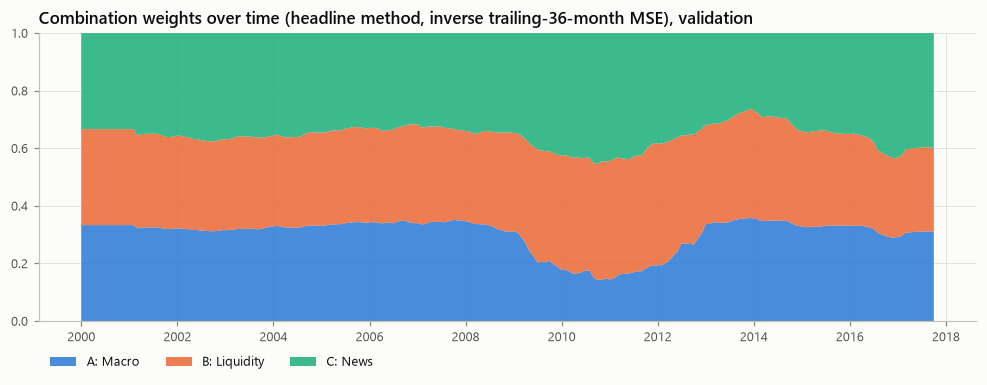

In [13]:
def combine(fc, y):
    """fc: DataFrame of group forecasts (contiguous months). Returns (combined forecast, weights)."""
    err2 = (fc.sub(y, axis=0)) ** 2
    W = pd.DataFrame(np.nan, index=fc.index, columns=fc.columns)
    for i in range(len(fc)):
        past = err2.iloc[max(0, i - 3 - COMB_WINDOW + 1): max(0, i - 2)]      # rows i-3-35 .. i-3 (realized)
        W.iloc[i] = (1 / past.mean()) / (1 / past.mean()).sum() if len(past) >= COMB_MIN else 1 / fc.shape[1]
    return (W * fc).sum(axis=1), W


def combo_forecasts(idx):
    out = {}
    for meth in ["selected", "Headline"]:
        fc = pd.DataFrame({g: F[(g, SELECTED[g] if meth == "selected" else meth)] for g in "ABC"}).loc[idx]
        out[meth] = combine(fc, df.loc[idx, "y"])
    return out


combo_idx = F[("A", "Headline")].index          # all validation forecasts (weights only use realized errors)
COMBO = combo_forecasts(combo_idx)
for meth, (f, W) in COMBO.items():
    F[("Combination", meth)] = f
val_combo = score([("Combination", "selected"), ("Combination", "Headline")], val_idx,
                  F[("bench", "Own history")], F[("bench", "Historical mean")])
display(val_combo.round(3))

fig, ax = plt.subplots(figsize=(11, 3.4))
W = COMBO["Headline"][1].loc[val_idx]
ax.stackplot(W.index.to_timestamp(), W.T.to_numpy(), labels=[f"{g}: {GROUP_NAMES[g]}" for g in W.columns],
             colors=PALETTE[:3], alpha=0.85)
ax.set_ylim(0, 1)
ax.set_title("Combination weights over time (headline method, inverse trailing-36-month MSE), validation")
ax.legend(loc="upper left", bbox_to_anchor=(0, -0.08), ncol=3)
save_fig(fig, "fig_combination_weights_validation")
plt.show()

In [14]:
# ---- Freeze the design. Everything the test run uses is written here, before any test forecast exists. ----
FROZEN = {"selected_method": SELECTED, "headline": "equal-weight Ridge + PCR",
          "windows": {"burn-in": "1987-01..1999-12", "validation (scored)": f"2000-01..{VAL_SCORE_END}",
                      "test": "2018-01..2025-09"},
          "refit": "yearly expanding; fit rows 1987-01..(Y-1)-10; hyperparameters re-tuned by purged blocked 5-fold CV",
          "combination": {"window": COMB_WINDOW, "min_errors": COMB_MIN},
          "grids": {"ridge_rel": [RIDGE_REL_GRID.min(), RIDGE_REL_GRID.max(), len(RIDGE_REL_GRID)],
                    "enet_rel": [ENET_REL_GRID.min(), ENET_REL_GRID.max(), len(ENET_REL_GRID)],
                    "enet_l1": ENET_L1_GRID, "rf": RF_GRID, "rf_trees": RF_TREES, "gb": GB_GRID,
                    "gb_max_trees": GB_MAX_TREES},
          "frozen_at": pd.Timestamp.now().isoformat(timespec="seconds")}
path = OUT / "frozen_design.json"
if not RUN_TEST:
    path.write_text(json.dumps(FROZEN, indent=2, default=str), encoding="utf-8")
    print(f"Design written to {path}")
else:
    saved = json.loads(path.read_text(encoding="utf-8"))
    assert saved["selected_method"] == SELECTED, "validation selections changed since the design was frozen"
    print(f"Test run: using the design frozen at {saved['frozen_at']}")
print(json.dumps(FROZEN["selected_method"], indent=1))

Design written to output\frozen_design.json
{
 "A": "Ridge",
 "B": "Lasso",
 "C": "OLS",
 "A+B": "Elastic net",
 "A+C": "Lasso",
 "B+C": "PLS",
 "A+B+C": "Elastic net"
}


## 8. Robustness (validation window only, so the test stays untouched)

1. **WSJ topics (group D) in place of news (C).** The WSJ data end in 2017-06, so this comparison uses validation rows 2000-01 to 2017-06, and C is re-scored on the same months.
2. **5- and 30-year Treasuries** in place of the 10-year: target, trailing correlation and own-history benchmark all rebuilt for that maturity.
3. **Rolling 15-year window** instead of expanding.
4. **Appendix: univariate models**, own history + one predictor at a time (OLS).

Robustness runs use the headline method (and, for D, also the method selected for C), so they do not add selection on top of the main analysis.

In [15]:
with timer("robustness: WSJ"):
    wsj_end = min(df[GROUPS["D"]].dropna().index[-1], VAL_END)        # WSJ data end 2017-06
    idx_d = df.loc[pd.Period("2000-01", "M"):min(wsj_end, VAL_SCORE_END)].index
    run(("D", "Ridge"), Ridge(), GROUPS["D"], end=wsj_end)
    run(("D", "PCR"), PCR(6), GROUPS["D"], end=wsj_end)
    run(("D", SELECTED["C"]), methods_for(6)[SELECTED["C"]], GROUPS["D"], end=wsj_end)
    F[("D", "Headline")] = (F[("D", "Ridge")] + F[("D", "PCR")]) / 2
    run(("bench_d", "Own history"), OwnHistory(), [], end=wsj_end)
    run(("bench_d", "Historical mean"), HistMean(), [], end=wsj_end)
rob_wsj = score([("C", "Headline"), ("D", "Headline"), ("C", SELECTED["C"]), ("D", SELECTED["C"])], idx_d,
                F[("bench_d", "Own history")], F[("bench_d", "Historical mean")])
rob_wsj.index = [f"{GROUP_NAMES[s]} ({m})" for s, m in rob_wsj.index]
rob_wsj.index.name = f"2000-01 to {wsj_end}"
display(rob_wsj.round(3))
save_table(rob_wsj, "table_robustness_wsj", "{:.3f}")

[robustness: WSJ: 0.2s]


,R2 vs own (%),R2 vs RW (%),R2 vs mean (%),sign (%),CW p vs own,CW p vs RW
2000-01 to 2017-06,,,,,,
News (Headline),7.492,0.772,73.261,77.619,0.002,0.000
WSJ topics (Headline),-6.837,-14.597,69.119,80.952,0.006,0.007
News (OLS),8.941,2.327,73.680,80.952,0.000,0.000
WSJ topics (OLS),-11.048,-19.113,67.902,81.429,0.003,0.003


In [16]:
rob_mat = {}
with timer("robustness: 5Y and 30Y Treasuries"):
    for mat in ["5Y", "30Y"]:
        d_m = df.copy()
        d_m["y"], d_m["h"] = targets[mat][0].loc[df.index], targets[mat][1].loc[df.index]
        own = recursive_forecasts(OwnHistory(), d_m, [], VAL_YEARS, VAL_END)[0]
        mean = recursive_forecasts(HistMean(), d_m, [], VAL_YEARS, VAL_END)[0]
        for s in ["A", "B", "C", "A+B+C"]:
            cols = set_cols(s)
            f = (recursive_forecasts(Ridge(), d_m, cols, VAL_YEARS, VAL_END)[0]
                 + recursive_forecasts(PCR(len(cols)), d_m, cols, VAL_YEARS, VAL_END)[0]) / 2
            y_, rw = d_m.loc[val_idx, "y"], d_m.loc[val_idx, "h"]
            rob_mat[(mat, s)] = {"R2 vs own (%)": oos_r2(y_, f.loc[val_idx], own.loc[val_idx]),
                                 "CW p vs own": clark_west(y_.to_numpy(), own.loc[val_idx].to_numpy(), f.loc[val_idx].to_numpy())[1],
                                 "R2 vs RW (%)": oos_r2(y_, f.loc[val_idx], rw),
                                 "own R2 vs mean (%)": oos_r2(y_, own.loc[val_idx], mean.loc[val_idx]),
                                 "own R2 vs RW (%)": oos_r2(y_, own.loc[val_idx], rw)}
    for s in ["A", "B", "C", "A+B+C"]:
        rob_mat[("10Y", s)] = {"R2 vs own (%)": val.loc[(s, "Headline"), "R2 vs own (%)"],
                               "CW p vs own": val.loc[(s, "Headline"), "CW p vs own"],
                               "R2 vs RW (%)": val.loc[(s, "Headline"), "R2 vs RW (%)"],
                               "own R2 vs mean (%)": bench_tab.loc["Own history", "R2 vs hist. mean (%)"],
                               "own R2 vs RW (%)": oos_r2(yv, own_v, df.loc[val_idx, "h"])}
rob_mat = pd.DataFrame(rob_mat).T.sort_index(level=0, key=lambda i: i.map({"5Y": 0, "10Y": 1, "30Y": 2}))
rob_mat.index.names = ["maturity", "own history + (headline)"]
display(rob_mat.round(3))
save_table(rob_mat, "table_robustness_maturity", "{:.3f}")

[robustness: 5Y and 30Y Treasuries: 1.0s]


R2 vs own (%)  CW p vs own  R2 vs RW (%)  own R2 vs mean (%)  own R2 vs RW (%)
maturity own history + (headline)                                                                                
5Y       A                               -15.721        0.049       -20.108              68.680            -3.791
         A+B+C                             0.491        0.102        -3.281              68.680            -3.791
         B                                -0.011        0.934        -3.802              68.680            -3.791
         C                                 9.850        0.000         6.432              68.680            -3.791
10Y      A                               -14.601        0.039       -22.614              70.923            -6.992
         A+B+C                             1.684        0.063        -5.190              70.923            -6.992
         B                                -0.011        0.954        -7.003              70.923            -6.992
         C                                 7.625        0.001         1.166              70.923            -6.992
30Y      A                               -13.826        0.043       -22.366              72.988            -7.503
         A+B+C                             3.554        0.020        -3.683              72.988            -7.503
         B                                -0.012        0.938        -7.516              72.988            -7.503
         C                                 9.269        0.001         2.461              72.988            -7.503

In [17]:
rob_roll = {}
with timer("robustness: rolling 15-year window"):
    own_r = recursive_forecasts(OwnHistory(), df, [], VAL_YEARS, VAL_END, window=ROLL_YEARS)[0]
    for s in ["A", "B", "C", "A+B+C"]:
        cols = set_cols(s)
        f = (recursive_forecasts(Ridge(), df, cols, VAL_YEARS, VAL_END, window=ROLL_YEARS)[0]
             + recursive_forecasts(PCR(len(cols)), df, cols, VAL_YEARS, VAL_END, window=ROLL_YEARS)[0]) / 2
        rob_roll[s] = {"R2 vs expanding own (%)": oos_r2(yv, f.loc[val_idx], own_v),
                       "R2 vs rolling own (%)": oos_r2(yv, f.loc[val_idx], own_r.loc[val_idx]),
                       "CW p vs rolling own": clark_west(y_v, own_r.loc[val_idx].to_numpy(), f.loc[val_idx].to_numpy())[1],
                       "R2 vs RW (%)": oos_r2(yv, f.loc[val_idx], df.loc[val_idx, "h"]),
                       "expanding, R2 vs own (%)": val.loc[(s, "Headline"), "R2 vs own (%)"]}
rob_roll = pd.DataFrame(rob_roll).T
rob_roll.index.name = "own history + (headline)"
print(f"Rolling own history vs expanding own history: R2 = {oos_r2(yv, own_r.loc[val_idx], own_v):.2f}%")
display(rob_roll.round(3))
save_table(rob_roll, "table_robustness_rolling", "{:.3f}")

[robustness: rolling 15-year window: 0.4s]
Rolling own history vs expanding own history: R2 = 8.57%


,R2 vs expanding own (%),R2 vs rolling own (%),CW p vs rolling own,R2 vs RW (%),"expanding, R2 vs own (%)"
own history + (headline),,,,,
A,-23.869,-35.487,0.038,-32.529,-14.601
B,1.674,-7.548,0.422,-5.200,-0.011
C,10.443,2.043,0.002,4.182,7.625
A+B+C,-30.763,-43.028,0.053,-39.906,1.684


In [18]:
uni = {}
with timer("appendix: univariate models"):
    for g in "ABCD":
        for c in GROUPS[g]:
            end = VAL_END if g != "D" else wsj_end
            idx = val_idx if g != "D" else idx_d
            ob = F[("bench", "Own history")] if g != "D" else F[("bench_d", "Own history")]
            f = recursive_forecasts(OLS(), df, [c], VAL_YEARS, end)[0]
            y_ = df.loc[idx, "y"]
            last = fit_rows(df, 2017)
            Z = np.column_stack([np.ones(len(last)), last["h"], (last[c] - last[c].mean()) / last[c].std()])
            uni[(GROUP_NAMES[g], c)] = {"R2 vs own (%)": oos_r2(y_, f.loc[idx], ob.loc[idx]),
                                        "R2 vs RW (%)": oos_r2(y_, f.loc[idx], df.loc[idx, "h"]),
                                        "CW p vs own": clark_west(y_.to_numpy(), ob.loc[idx].to_numpy(), f.loc[idx].to_numpy())[1],
                                        "coef per sd (2017 fit)": np.linalg.lstsq(Z, last["y"], rcond=None)[0][2]}
uni = pd.DataFrame(uni).T
uni.index.names = ["group", "predictor"]
display(uni.round(3))
save_table(uni, "table_appendix_univariate", "{:.3f}")

[appendix: univariate models: 1.1s]


R2 vs own (%)  R2 vs RW (%)  CW p vs own  coef per sd (2017 fit)
group      predictor                                                                               
Macro      infl_yoy                        0.448        -6.512        0.131                   0.038
           infl_vol12                     -6.895       -14.369        0.143                  -0.043
           exp_infl_mich                  -3.268       -10.488        0.608                   0.007
           unemp_chg12                    -1.610        -8.714        0.084                  -0.028
           tbill                           7.440         0.968        0.001                   0.097
           term_spread                    -5.339       -12.704        0.960                  -0.018
Liquidity  credit_spread                  -5.689       -13.079        0.956                  -0.011
           cp_spread                      -2.312        -9.465        0.820                   0.022
           vix_monthend                   -0.464        -7.488        0.775                   0.003
           treasury_noise                 -1.344        -8.430        0.303                   0.018
           ps_liquidity                   -0.134        -7.135        0.465                  -0.018
News       epu_overall                    -0.137        -7.138        0.143                   0.036
           epu_monetary                    2.076        -4.771        0.026                   0.042
           emv_inflation_share             2.166        -4.674        0.022                   0.075
           emv_rates_share                 4.388        -2.296        0.010                   0.081
           emv_monetary_share             -0.860        -7.912        0.676                  -0.023
           emv_macro_news_share           -5.272       -12.632        0.642                   0.008
WSJ topics wsj_Federal Reserve            -2.574       -10.024        0.647                   0.001
           wsj_Recession                  -1.419        -8.785        0.459                  -0.017
           wsj_Oil market                 -0.420        -7.714        0.458                  -0.025
           wsj_Treasury bonds             14.477         8.265        0.000                   0.131
           wsj_Financial crisis          -19.696       -28.390        0.012                  -0.059
           wsj_Government budgets         -9.188       -17.119        0.403                   0.032

## 9. Test window, run once (Table 1)

This section runs only when `RUN_TEST = True`. Set it in the setup cell **once**, after the team has agreed the design is final, and rerun the whole notebook. The run:
1. checks that the validation selections still match `output/frozen_design.json`;
2. forecasts 2018-01 to 2025-09 with the same yearly expanding refits and per-refit CV tuning;
3. fills Table 1 and applies the pre-registered decision rule;
4. reports full 2000–2025 results for the headline method only (clean, because nothing about it was chosen on validation);
5. writes timestamped outputs that must not be changed afterwards.

In [19]:
if not RUN_TEST:
    print("RUN_TEST = False: the test window has not been touched. No test forecasts were computed.")
else:
    with timer("test window"):
        run(("bench", "Historical mean"), HistMean(), [], TEST_YEARS, TEST_END)
        run(("bench", "Own history"), OwnHistory(), [], TEST_YEARS, TEST_END)
        for s in SETS:
            cols = set_cols(s)
            for mname in {SELECTED[s], "Ridge", "PCR"}:
                f_val = F[(s, mname)]
                run((s, mname), methods_for(len(cols))[mname], cols, TEST_YEARS, TEST_END)
                F[(s, mname)] = pd.concat([f_val, F[(s, mname)]])          # keep validation forecasts too
            F[(s, "Headline")] = (F[(s, "Ridge")] + F[(s, "PCR")]) / 2
        # benchmarks: rerun over validation + test so the full-period table has them
        for b, m in [("Historical mean", HistMean()), ("Own history", OwnHistory())]:
            run(("bench", b), m, [], VAL_YEARS + TEST_YEARS, TEST_END)
        all_idx = F[("A", "Headline")].index
        COMBO = combo_forecasts(all_idx)              # weights at each month use only realized past errors
        for meth, (f, W) in COMBO.items():
            F[("Combination", meth)] = f

    own_t, mean_t = F[("bench", "Own history")], F[("bench", "Historical mean")]
    y_t = df.loc[test_idx, "y"].to_numpy()
    rows = {"Own history": ("bench", "Own history")}
    for s in ["A", "B", "C", "A+B", "A+B+C"]:
        rows[f"+ {s}"] = (s, SELECTED[s])
    rows["Accuracy-weighted combination"] = ("Combination", "selected")
    for s in ["A", "B", "C", "A+B+C"]:
        rows[f"+ {s}, headline"] = (s, "Headline")
    rows["Combination, headline"] = ("Combination", "Headline")
    t1 = score(list(rows.values()), test_idx, own_t, mean_t)
    t1.index = list(rows)
    t1.insert(0, "method", [k[1] if k[0] != "bench" else "—" for k in rows.values()])
    t1.loc["Own history", ["R2 vs own (%)", "CW p vs own"]] = [0.0, np.nan]
    rw_row = {"method": "—", "R2 vs own (%)": oos_r2(df.loc[test_idx, "y"], df.loc[test_idx, "h"], own_t.loc[test_idx]),
              "R2 vs RW (%)": 0.0, "R2 vs mean (%)": oos_r2(df.loc[test_idx, "y"], df.loc[test_idx, "h"], mean_t.loc[test_idx]),
              "sign (%)": sign_acc(df.loc[test_idx, "y"], df.loc[test_idx, "h"]), "CW p vs own": np.nan, "CW p vs RW": np.nan}
    t1 = pd.concat([pd.DataFrame([rw_row], index=["Random walk (trailing correlation)"]), t1])
    t1.index.name = "model (test 2018-01 to 2025-09)"
    display(t1)

    # ---- pre-registered decision rule ----
    def decide(meth_label):
        keys = {g: (g, SELECTED[g] if meth_label == "selected" else "Headline") for g in "ABC"}
        r2 = {g: oos_r2(df.loc[test_idx, "y"], F[k].loc[test_idx], own_t.loc[test_idx]) for g, k in keys.items()}
        cw = {g: clark_west(y_t, own_t.loc[test_idx].to_numpy(), F[k].loc[test_idx].to_numpy())[1] for g, k in keys.items()}
        rank = sorted(r2, key=r2.get, reverse=True)
        adders = [g for g in rank if cw[g] < 0.05]
        if not adders:
            return rank, "No group adds value beyond own history (Clark-West p >= 0.05 for A, B and C)."
        win = adders[0]
        others = [g for g in rank if g != win]
        runner = others[0]
        t, p = diebold_mariano(y_t, F[keys[runner]].loc[test_idx].to_numpy(), F[keys[win]].loc[test_idx].to_numpy())
        clear = p < 0.05 and t > 0
        return rank, (f"Winner: {win} ({GROUP_NAMES[win]}), R2 vs own {r2[win]:.2f}%, CW p {cw[win]:.3f}. "
                      + (f"Clear winner: DM vs {runner} t = {t:.2f}, p = {p:.3f}." if clear else
                         f"Not distinguishable from {runner} (DM t = {t:.2f}, p = {p:.3f})."))

    for meth in ["selected", "headline"]:
        rank, verdict = decide(meth)
        print(f"[{meth} methods] ranking by test R2 vs own: {' > '.join(rank)}.  {verdict}")

    full_idx = F[("A", "Headline")].index[F[("A", "Headline")].index.isin(val_idx.append(test_idx))]
    full = score([(s, "Headline") for s in SETS] + [("Combination", "Headline")], full_idx, own_t, mean_t)
    full.index = [f"+ {s}" if s != "Combination" else "Combination" for s, _ in full.index]
    full.index.name = "headline, 2000-01 to 2025-09 (excl. 2017-11/12)"
    display(full.round(3))

    stamp = pd.Timestamp.now().strftime("%Y%m%d_%H%M%S")
    save_table(t1, f"table1_test_{stamp}", "{:.3f}")
    save_table(full, f"table_full_period_headline_{stamp}", "{:.3f}")
    print(f"Test results saved with stamp {stamp}. Do not change the design after this point.")

RUN_TEST = False: the test window has not been touched. No test forecasts were computed.


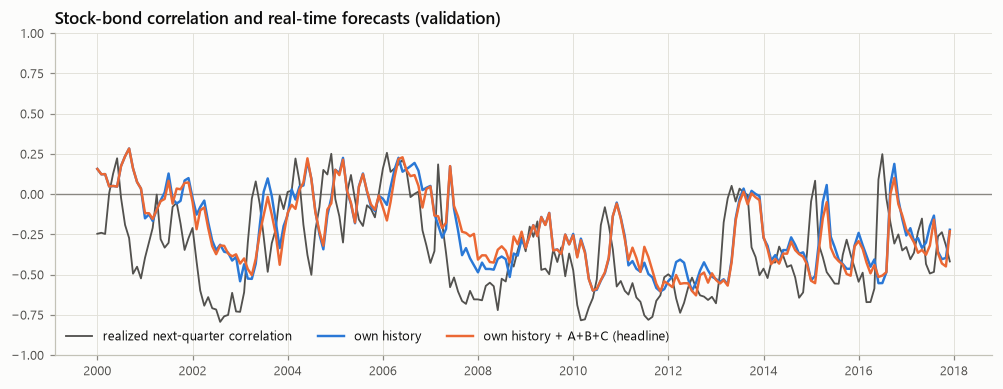

In [20]:
# Correlation history with forecasts (validation; test months are added only after the test run).
fig, ax = plt.subplots(figsize=(11, 3.8))
idx = F[("A", "Headline")].index
t = idx.to_timestamp()
ax.plot(df.loc[idx].index.to_timestamp(), df.loc[idx, "y"], color=INK2, linewidth=1.2, label="realized next-quarter correlation")
ax.plot(t, F[("bench", "Own history")].loc[idx], color=PALETTE[0], label="own history")
ax.plot(t, F[("A+B+C", "Headline")].loc[idx], color=PALETTE[1], label="own history + A+B+C (headline)")
if RUN_TEST:
    ax.axvline(pd.Period("2018-01", "M").to_timestamp(), color=MUTED, linestyle="--", linewidth=1)
zero_line(ax)
ax.set_ylim(-1, 1)
ax.set_title("Stock-bond correlation and real-time forecasts" + (" (validation and test)" if RUN_TEST else " (validation)"))
ax.legend(loc="lower left", ncol=3)
save_fig(fig, "fig_forecasts" + ("_test" if RUN_TEST else "_validation"))
plt.show()

## Notes for the paper

* **Design changes relative to the team instructions doc:** hyperparameters are re-tuned by purged blocked CV at every yearly refit, and the windows are labeled burn-in / validation / test. The last two validation rows are not scored (overlap with test targets).
* **Caveats:** the burn-in lies entirely in the positive-correlation regime, so early validation years are hard for every model; 1987–99 data still makes up about 34–42% of each test-period fit. Validation $R^2$ for the *selected* methods is optimistic because selection happened there; only test results and the headline results are clean. The test window has about 31 independent quarters, so tests have low power, and a null result is informative.